# 05 · Faithfulness and comparative evaluation

**Research question 3.** Is the reliability-weighted fused map more faithful to the CNNs than fused maps without stability, than random deletion,
and than its own components? Does waveform conditioning (Module 3B) help?

**Paired block deletion.** Each map is resampled to the 5000 raw samples. For deletion fraction $f\in\{0.05,\dots,0.30\}$,
$n_f=\mathrm{round}(5000f/50)$ non-overlapping 50-sample blocks are chosen greedily by mean attribution and replaced by linear interpolation.
The 1D CNN receives the modified signal and the 2D CNN a re-rendered image. With $d_m(f)$ the drop in true-class probability,
$$\mathrm{AUC}_m=\int_0^{0.30} d_m(f)\,df\ \text{(trapezoid, anchored at }(0,0)),\qquad \Delta\mathrm{AUC}_m=\mathrm{AUC}_m-\mathrm{AUC}_R ,$$
compared per recording (paired), with a 2000-resample bootstrap over recordings. Random control: same number of random blocks, five replicates.

**Data.** 693 Module 3B recordings were submitted; 692 passed the strict check that the archived baseline probability is reproduced (tolerance $10^{-5}$); ECG 406 failed and is not imputed.
The deletion runs were executed on the HPC (`module3_faithfulness.py`, one SLURM array task per recording); this notebook re-checks every raw file and recomputes all statistics.

> **Code on GitHub.** The re-run of the MM-GradCAM anchor (cohort, frozen split, 1D/2D CNN training and test-split manifests) is on the `main` branch of <https://github.com/dwiharyani/dan-mmgradcam-anchor-replication>. The Grad-CAM temporal alignment and the Module 1 alignment code are on the `module1-nahida` branch of the same repository. The same scripts are also included in `src/hpc_pipeline/` of the submitted package.

> **Google Colab:** upload `DAN-MMGradCAM_COE691.zip` (Files panel), then run `!unzip -q DAN-MMGradCAM_COE691.zip -d /content` once in a code cell. The setup cell below finds the folder automatically. **Jupyter:** open this notebook from the `notebooks/` folder of the extracted package.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

def find_root():
    """Repository root: works from notebooks/, from the root itself, and in Google Colab (/content)."""
    here = Path.cwd().resolve()
    for p in [here, *here.parents, Path('/content/DAN-MMGradCAM'), Path('/content/drive/MyDrive/DAN-MMGradCAM')]:
        if (p / 'data' / 'archived').is_dir() and (p / 'src').is_dir():
            return p
    raise FileNotFoundError('DAN-MMGradCAM folder not found. In Colab, upload DAN-MMGradCAM_COE691.zip and run: '
                            '!unzip -q DAN-MMGradCAM_COE691.zip -d /content')
ROOT = find_root()                          # repository root
sys.path.insert(0, str(ROOT / 'src'))
ARCH = ROOT / 'data' / 'archived'           # archived HPC outputs (inputs of this notebook)
TAB = ROOT / 'results' / 'tables'           # tables written by the notebooks
FIG = ROOT / 'results' / 'figures'          # figures written by the notebooks (used in the report)
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore', category=RuntimeWarning)
CLASSES = ['AFib', 'GSVT', 'SB', 'SR']
def show(name, width=900):
    """Display a figure that a plotting function saved to results/figures."""
    display(Image(filename=str(FIG / f'{name}.png'), width=width))
print('repository root:', ROOT.name)

repository root: DAN-MMGradCAM


## 1. Quality control of the 692 raw result files

In [2]:
RAW = ARCH / 'faithfulness_cohort/raw'
FRACTIONS = np.array([0.05, 0.10, 0.15, 0.20, 0.25, 0.30])
CORE = {'R', 'Fbase', 'Rtrace_0p5', 'Rtrace_1p0', 'Rtrace_2p0'}
expected = set(range(693)) - {602}                    # index 602 = ECG 406, failed baseline QC
csvs = {int(p.stem.split('_')[1]): p for p in RAW.glob('faith_????.csv')}
audits = {int(p.stem.split('_')[1]): p for p in RAW.glob('faith_????_audit.json')}
assert set(csvs) == expected and set(audits) == expected
m3_ids = np.load(ARCH / 'module3b/module3b_maps.npz')['cohort_index'].astype(int)
frames, aud = [], []
for k in sorted(expected):
    meta = json.loads(audits[k].read_text()); df = pd.read_csv(csvs[k])
    assert meta['strict_baseline_qc'] is True and meta['oneDNN_disabled'] is True
    assert int(meta['cohort_index']) == m3_ids[k] and set(df.cohort_index) == {m3_ids[k]}
    assert set(df.block_samples) == {50} and np.allclose(df.actual_fraction, df.fraction)
    assert np.isfinite(df[['probability_drop', 'baseline_probability', 'perturbed_probability']].to_numpy(float)).all()
    for b in ('1d', '2d'):
        r = df[(df.branch == b) & (df.control == 'random')]
        assert len(r) == 30 and CORE <= set(df[(df.branch == b) & (df.control == 'attribution')].method)
    frames.append(df.assign(index=k)); aud.append(meta)
raw = pd.concat(frames, ignore_index=True); aud = pd.DataFrame(aud)
print('recordings:', raw.cohort_index.nunique(), '| rows:', len(raw), '| matched-30:', int(aud.matched30.sum()))
print('max baseline reproduction error 1D: %.1e, 2D: %.1e' % (aud.baseline_1d_max_error.max(), aud.baseline_2d_max_error.max()))
print('TensorFlow on the HPC:', aud.tensorflow_version.unique(), '| class counts:', raw.drop_duplicates('cohort_index').class_name.value_counts().to_dict())

recordings: 692 | rows: 89652 | matched-30: 551
max baseline reproduction error 1D: 6.1e-06, 2D: 9.1e-06
TensorFlow on the HPC: <StringArray>
['2.19.0']
Length: 1, dtype: str | class counts: {'SB': 200, 'GSVT': 184, 'AFib': 182, 'SR': 126}


## 2. Deletion AUC per recording and paired comparison with $R$

In [3]:
integrate = getattr(np, 'trapezoid', None) or np.trapz
def auc(g):
    g = g.groupby('fraction').probability_drop.mean().sort_index()
    assert np.allclose(g.index, FRACTIONS)
    return float(integrate(np.r_[0., g.to_numpy()], np.r_[0., FRACTIONS]))
A = (raw.groupby(['index', 'cohort_index', 'class_name', 'branch', 'method']).apply(auc)
        .rename('auc_drop').reset_index())
A.to_csv(TAB / 'faithfulness_auc_per_record.csv', index=False)

def bootstrap_mean(v, seed):
    v = np.asarray(v, float); rng = np.random.default_rng(seed)
    b = v[rng.integers(len(v), size=(2000, len(v)))].mean(1)
    return v.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

rows = []
for b in ('1d', '2d'):
    for cl in ['ALL'] + CLASSES:
        sub = A[A.branch == b] if cl == 'ALL' else A[(A.branch == b) & (A.class_name == cl)]
        pt = sub.pivot(index='cohort_index', columns='method', values='auc_drop')
        for m in ['Fbase', 'Fmu_matched30', 'RANDOM', 'Rtrace_0p5', 'Rtrace_1p0', 'Rtrace_2p0']:
            mt = pt[['R', m]].dropna(); d = mt[m] - mt['R']
            seed = 20261115 + len(d) + len(m) + len(cl) + len(b)          # same seeds as the HPC summary script
            mean, lo, hi = bootstrap_mean(d, seed)
            rows.append({'branch': b, 'class_name': cl, 'comparison': f'{m} - R', 'n_ecg': len(d),
                         'mean_delta_auc': mean, 'ci95_lower': lo, 'ci95_upper': hi})
paired = pd.DataFrame(rows); paired.to_csv(TAB / 'faithfulness_paired_delta_auc.csv', index=False)
hpc = pd.read_csv(ROOT / 'data/archived/faithfulness_cohort/hpc_paired_auc_summary.csv')
chk = paired.merge(hpc, on=['branch', 'class_name', 'comparison'], suffixes=('', '_hpc'))
print('rows compared with the HPC summary:', len(chk), '| max |difference| of mean ΔAUC: %.1e, of CI bounds: %.1e' % (
      (chk.mean_delta_auc - chk.mean_delta_auc_hpc).abs().max(),
      max((chk.ci95_lower - chk.ci95_lower_hpc).abs().max(), (chk.ci95_upper - chk.ci95_upper_hpc).abs().max())))
main = paired[paired.class_name == 'ALL'].copy()
main['significant'] = np.where(main.ci95_lower > 0, 'method > R', np.where(main.ci95_upper < 0, 'method < R', 'n.s.'))
main.round(4)

rows compared with the HPC summary: 60 | max |difference| of mean ΔAUC: 9.9e-17, of CI bounds: 9.9e-17


,branch,class_name,comparison,n_ecg,mean_delta_auc,ci95_lower,ci95_upper,significant
0,1d,ALL,Fbase - R,692,0.0002,-0.0025,0.0028,n.s.
1,1d,ALL,Fmu_matched30 - R,551,-0.0008,-0.0032,0.0018,n.s.
2,1d,ALL,RANDOM - R,692,-0.0131,-0.0169,-0.0098,method < R
3,1d,ALL,Rtrace_0p5 - R,692,0.0152,0.0118,0.0189,method > R
4,1d,ALL,Rtrace_1p0 - R,692,0.0308,0.0261,0.0357,method > R
5,1d,ALL,Rtrace_2p0 - R,692,0.0475,0.0411,0.0542,method > R
30,2d,ALL,Fbase - R,692,-0.0035,-0.0054,-0.0017,method < R
31,2d,ALL,Fmu_matched30 - R,551,-0.0030,-0.0047,-0.0012,method < R
32,2d,ALL,RANDOM - R,692,0.0026,-0.0003,0.0055,n.s.
33,2d,ALL,Rtrace_0p5 - R,692,0.0162,0.0136,0.0189,method > R


In [4]:
absA = (A.groupby(['branch', 'method']).auc_drop.agg(['count', 'mean'])
          .rename(columns={'count': 'n', 'mean': 'mean AUC (prob. drop × fraction)'}))
absA.to_csv(TAB / 'faithfulness_auc_by_method.csv'); absA.round(4)

n  mean AUC (prob. drop × fraction)
branch method                                              
1d     Fbase          692                            0.0264
       Fmu_matched30  551                            0.0159
       R              692                            0.0262
       RANDOM         692                            0.0131
       Rtrace_0p5     692                            0.0415
       Rtrace_1p0     692                            0.0570
       Rtrace_2p0     692                            0.0737
2d     Fbase          692                            0.0181
       Fmu_matched30  551                            0.0142
       R              692                            0.0216
       RANDOM         692                            0.0242
       Rtrace_0p5     692                            0.0378
       Rtrace_1p0     692                            0.0511
       Rtrace_2p0     692                            0.0731

**Reading (692 recordings).**
* **Against other fused maps**, stability weighting helps the 2D CNN: $R$ is more faithful than $F_{\mathrm{base}}$ and $F_{\mu}$ (ΔAUC < 0 with CI below 0); for the 1D CNN the three fusions are equivalent.
* **Against random deletion**, $R$ is better for the 1D CNN but not for the 2D CNN.
* **Module 3B** raises AUC monotonically with $\lambda$ in both CNNs, but notebook 04 shows that part of this comes from moving attribution to steep QRS columns, so the gain is reported as exploratory.

saved fig_module3_faith692
saved col_module3_faith692


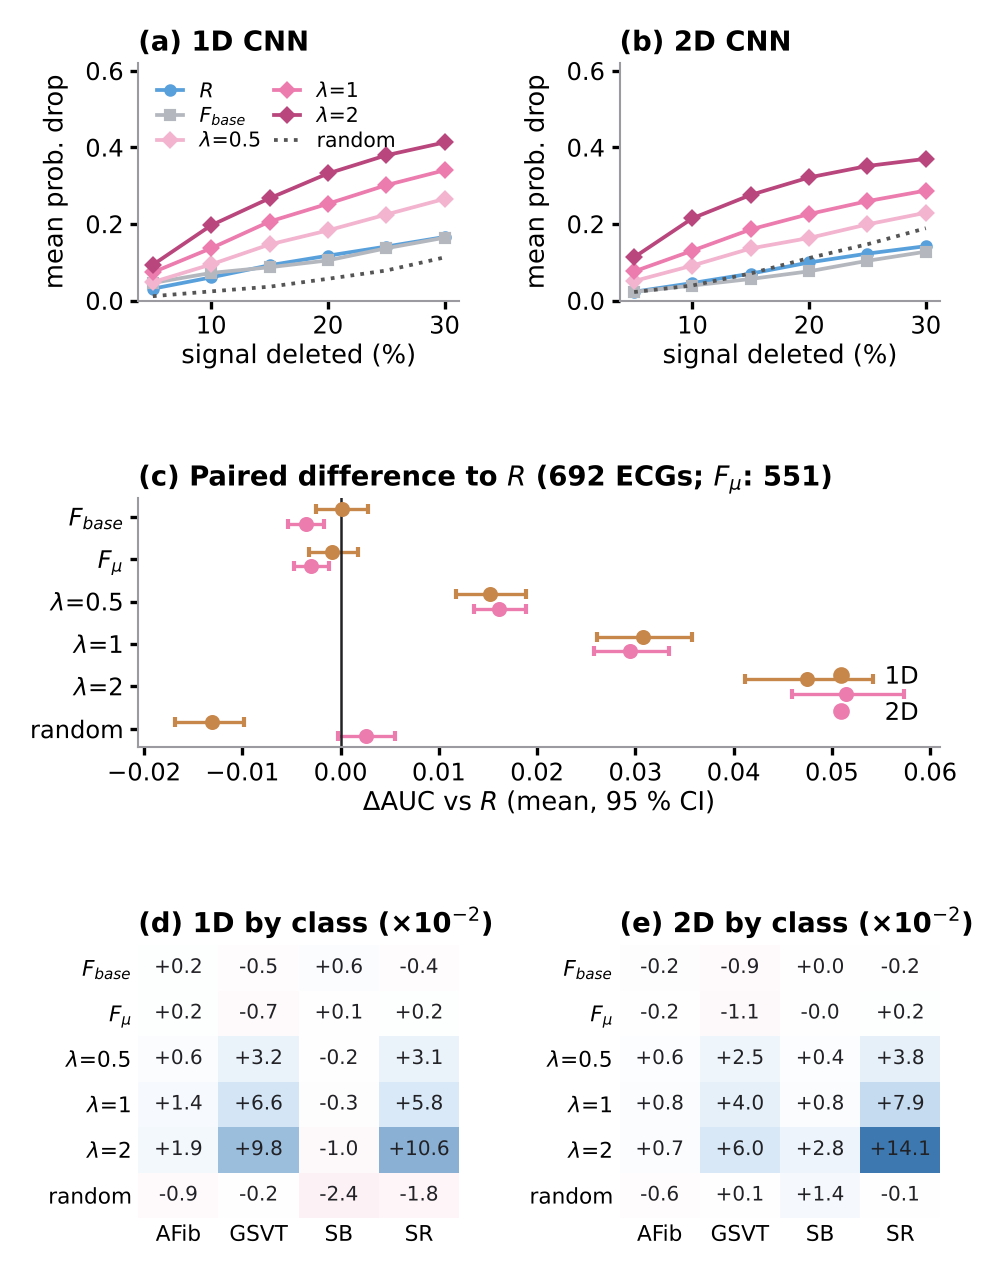

In [5]:
import dan_figures as F
curves_att = raw[raw.control == 'attribution'].groupby(['branch', 'method', 'fraction']).probability_drop.mean().reset_index()
rnd = raw[raw.control == 'random'].groupby(['cohort_index', 'branch', 'fraction']).probability_drop.mean().reset_index()
curves = pd.concat([curves_att, rnd.groupby(['branch', 'fraction']).probability_drop.mean().reset_index().assign(method='RANDOM')])
curves.to_csv(TAB / 'faithfulness_deletion_curves.csv', index=False)
F.fig_faith692(curves, paired, FIG)
import dan_column_figures as C
C.fig_faith692_column(curves, paired, FIG)        # single-column version used in the report
show('col_module3_faith692', 420)

## 3. Component analysis: is the fused map as faithful as its components? (100 recordings, 25 per class)

The earlier deletion run (same protocol, AOPC-style mean drop over fractions minus matched random deletion) compares, per branch, the raw Grad-CAM,
the stability-weighted map $H=\mu S$ and the fused map $R$.

In [6]:
rng = np.random.default_rng(20261117)
cr = pd.read_csv(ARCH / 'faithfulness_component/deletion_raw_results.csv')
agg = cr.groupby(['cohort_index', 'class_name', 'branch', 'method', 'control']).probability_drop.mean().unstack('control').reset_index()
agg['gain'] = agg.attribution - agg.random
def boot(x):
    b = [rng.choice(x, x.size).mean() for _ in range(2000)]; return np.percentile(b, [2.5, 97.5])
rows = []
for (b, m), g in agg.groupby(['branch', 'method']):
    lo, hi = boot(g.gain.to_numpy())
    rows.append({'branch': b, 'method': m, 'n': len(g), 'gain over random (mean)': g.gain.mean(), 'CI lo': lo, 'CI hi': hi,
                 '% records gain > 0': 100 * (g.gain > 0).mean()})
comp = pd.DataFrame(rows); comp.to_csv(TAB / 'component_gain_over_random.csv', index=False)
pairs = []
for b, H, base in (('1d', 'H1', 'base1'), ('2d', 'H2', 'base2')):
    g = agg[agg.branch == b].pivot(index='cohort_index', columns='method', values='attribution')
    for a_, b_ in ((H, base), ('R', H), ('R', base)):
        d = (g[a_] - g[b_]).dropna().to_numpy(); lo, hi = boot(d)
        pairs.append({'branch': b, 'comparison': f'{a_} - {b_}', 'n': len(d), 'mean diff': d.mean(), 'CI lo': lo, 'CI hi': hi})
pairs = pd.DataFrame(pairs); pairs.to_csv(TAB / 'component_paired.csv', index=False)
display(comp.round(4)); display(pairs.round(4))
from scipy.stats import wilcoxon, spearmanr
for b, H, base in (('1d', 'H1', 'base1'), ('2d', 'H2', 'base2')):
    g = agg[agg.branch == b].pivot(index='cohort_index', columns='method', values='attribution')
    print(b.upper(), ' | '.join(f'{x} vs {y}: Wilcoxon p = {wilcoxon(g[x], g[y]).pvalue:.1e}' for x, y in ((H, base), ('R', H), ('R', base))))

,branch,method,n,gain over random (mean),CI lo,CI hi,% records gain > 0
0,1d,H1,100,0.0718,0.0358,0.1113,65.0
1,1d,R,100,0.0272,-0.0039,0.0617,51.0
2,1d,base1,100,0.0698,0.0352,0.1083,62.0
3,2d,H2,100,0.0167,-0.0117,0.0452,46.0
4,2d,R,100,-0.0337,-0.0615,-0.0036,31.0
5,2d,base2,100,-0.0676,-0.0966,-0.0406,20.0


,branch,comparison,n,mean diff,CI lo,CI hi
0,1d,H1 - base1,100,0.0020,-0.0191,0.0242
1,1d,R - H1,100,-0.0446,-0.0752,-0.0179
2,1d,R - base1,100,-0.0426,-0.0718,-0.0147
3,2d,H2 - base2,100,0.0843,0.0518,0.1215
4,2d,R - H2,100,-0.0504,-0.0907,-0.0121
5,2d,R - base2,100,0.0340,0.0052,0.0621


1D H1 vs base1: Wilcoxon p = 3.5e-01 | R vs H1: Wilcoxon p = 2.2e-04 | R vs base1: Wilcoxon p = 2.1e-06
2D H2 vs base2: Wilcoxon p = 1.5e-08 | R vs H2: Wilcoxon p = 2.6e-03 | R vs base2: Wilcoxon p = 1.0e-01


In [7]:
m1o = pd.read_csv(TAB / 'module1_per_record.csv').set_index('cohort_index').O
s2m = pd.read_csv(ARCH / 'module2/noise_stability_records.csv').set_index('cohort_index').S2_mean
win = {}
for b, H, base in (('1d', 'H1', 'base1'), ('2d', 'H2', 'base2')):
    g = agg[agg.branch == b].pivot(index='cohort_index', columns='method', values='attribution')
    pen = g['R'] - g[H]
    ro, po = spearmanr(pen, m1o.reindex(pen.index)); rs, ps = spearmanr(pen, s2m.reindex(pen.index))
    win[b] = 100 * ((g['R'] > g[H]) & (g['R'] > g[base])).mean()
    print(f'{b.upper()}: fusion penalty R - {H} vs Module 1 shared mass O: rho = {ro:.2f} (p = {po:.2f}); '
          f'vs mean S2: rho = {rs:.2f} (p = {ps:.3f}); R above both branch maps in {win[b]:.0f} % of recordings')

1D: fusion penalty R - H1 vs Module 1 shared mass O: rho = 0.02 (p = 0.83); vs mean S2: rho = -0.11 (p = 0.283); R above both branch maps in 13 % of recordings
2D: fusion penalty R - H2 vs Module 1 shared mass O: rho = 0.03 (p = 0.77); vs mean S2: rho = 0.23 (p = 0.021); R above both branch maps in 26 % of recordings


In [8]:
bycls = agg.groupby(['branch', 'method', 'class_name']).gain.mean().unstack('class_name')[CLASSES]
bycls.to_csv(TAB / 'component_gain_by_class.csv')
print('Gain over random deletion by class (100 recordings, 25 per class):')
bycls.round(3)

Gain over random deletion by class (100 recordings, 25 per class):


class_name      AFib   GSVT     SB     SR
branch method                            
1d     H1      0.074  0.029  0.076  0.108
       R       0.022 -0.023  0.054  0.055
       base1   0.065  0.064  0.055  0.095
2d     H2      0.031 -0.044  0.068  0.011
       R       0.033 -0.034 -0.061 -0.072
       base2   0.027 -0.169 -0.035 -0.094

saved fig_component_faithfulness


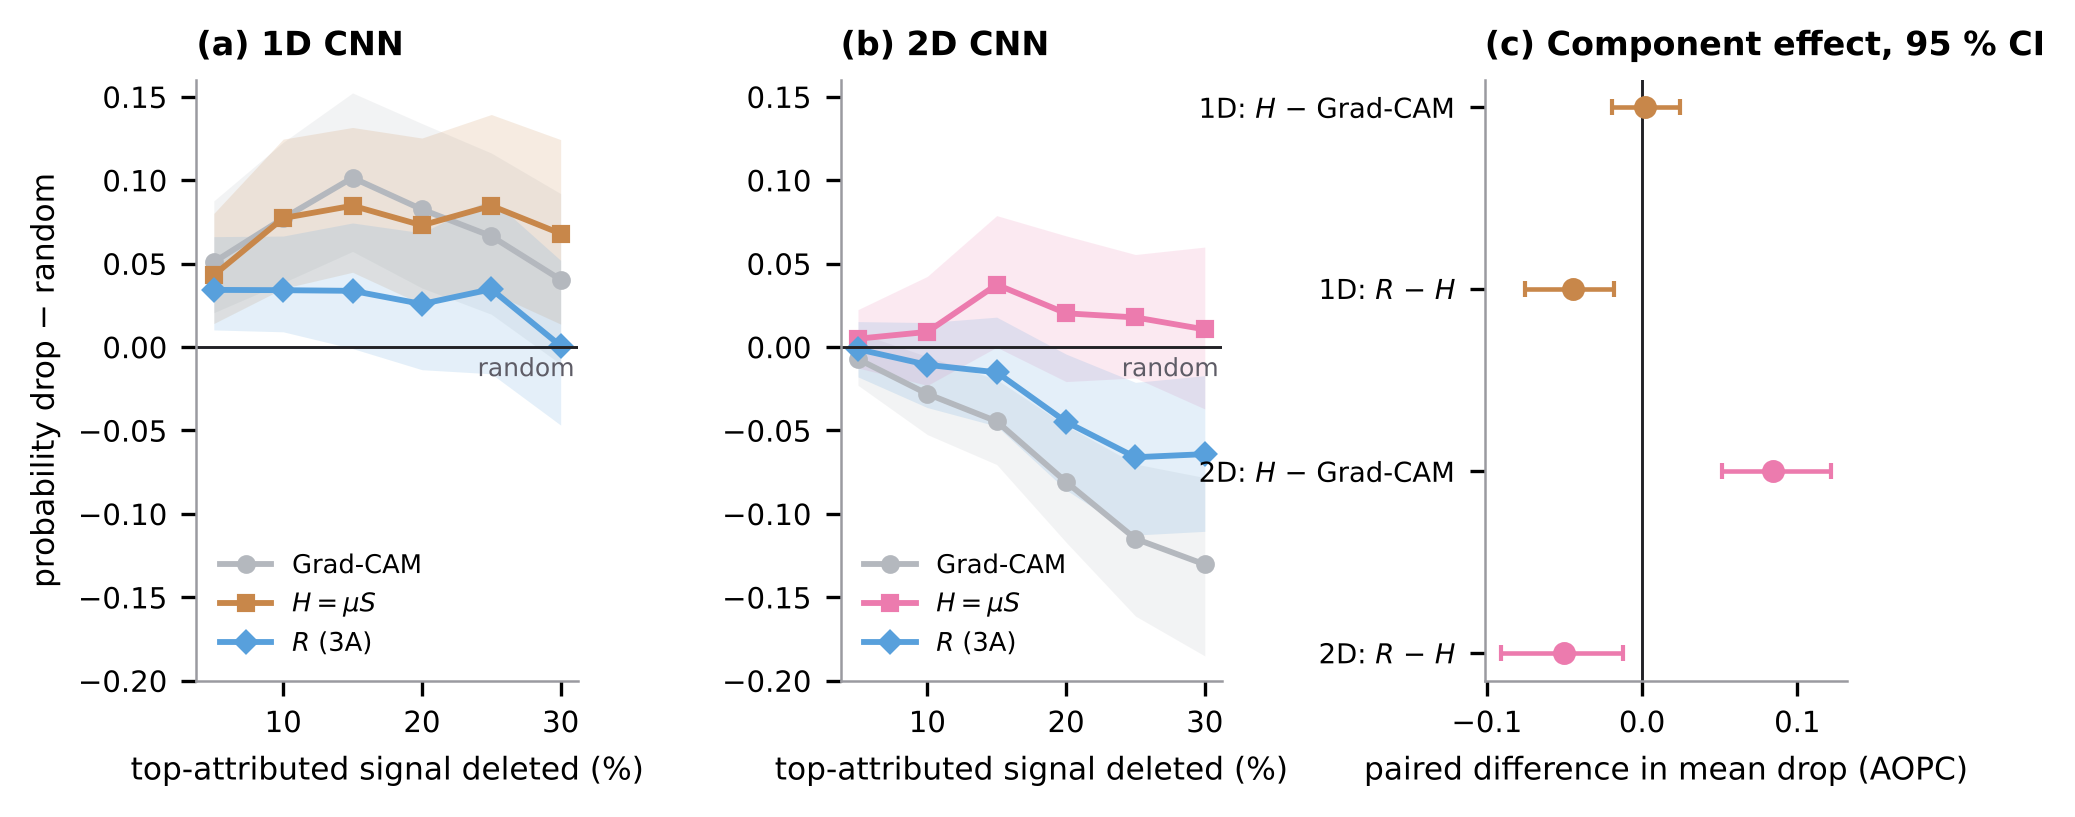

In [9]:
summ = pd.read_csv(ARCH / 'faithfulness_component/deletion_summary_bootstrap.csv')
F.fig_faith(summ, pairs.rename(columns={'mean diff': 'mean_diff', 'CI lo': 'ci_lo', 'CI hi': 'ci_hi'}), FIG)
show('fig_component_faithfulness', 750)

## 4. Comparative evaluation summary

In [10]:
def verdict(b, comp_):
    r = main[(main.branch == b) & (main.comparison == comp_)].iloc[0]
    return f"{r.mean_delta_auc:+.3f} [{r.ci95_lower:+.3f}, {r.ci95_upper:+.3f}]"
summary = pd.DataFrame({
    'comparison (method − R, ΔAUC, 95% CI)': ['anchor-style fusion F_base', 'fusion without stability F_mu (551)', 'random deletion',
                                              'R_trace λ=0.5', 'R_trace λ=1', 'R_trace λ=2'],
    '1D CNN': [verdict('1d', c) for c in ['Fbase - R', 'Fmu_matched30 - R', 'RANDOM - R', 'Rtrace_0p5 - R', 'Rtrace_1p0 - R', 'Rtrace_2p0 - R']],
    '2D CNN': [verdict('2d', c) for c in ['Fbase - R', 'Fmu_matched30 - R', 'RANDOM - R', 'Rtrace_0p5 - R', 'Rtrace_1p0 - R', 'Rtrace_2p0 - R']]})
summary.to_csv(TAB / 'comparative_evaluation_summary.csv', index=False); summary

,"comparison (method − R, ΔAUC, 95% CI)",1D CNN,2D CNN
0,anchor-style fusion F_base,"+0.000 [-0.003, +0.003]","-0.004 [-0.005, -0.002]"
1,fusion without stability F_mu (551),"-0.001 [-0.003, +0.002]","-0.003 [-0.005, -0.001]"
2,random deletion,"-0.013 [-0.017, -0.010]","+0.003 [-0.000, +0.005]"
3,R_trace λ=0.5,"+0.015 [+0.012, +0.019]","+0.016 [+0.014, +0.019]"
4,R_trace λ=1,"+0.031 [+0.026, +0.036]","+0.029 [+0.026, +0.033]"
5,R_trace λ=2,"+0.047 [+0.041, +0.054]","+0.051 [+0.046, +0.057]"


Negative values mean the method is **less** faithful than $R$. The fused map is a small improvement over fused maps without stability (2D CNN),
it is not better than random deletion for the 2D CNN, and in the component study it is less faithful than each branch's own stability-weighted map.
Fused explanations should therefore be reported together with their components and their disagreement.